In [1]:
from pathlib import Path
import subprocess
import sys
from google.colab import drive

DRIVE = Path('/content/drive')
drive.mount('/content/drive')

ROOT = DRIVE / "MyDrive" / "doctorado/materias/ml_geofluidos_inv/tp_final/codigos_eval"
assert ROOT.exists()
PACKAGE_DIR = ROOT / 'python_packages'
PACKAGE_DIR.mkdir(exist_ok=True)

sys.path.insert(0, str(PACKAGE_DIR))
print(PACKAGE_DIR.resolve())


if not (PACKAGE_DIR / 'cartopy').exists():
    subprocess.check_call([
        sys.executable, '-m', 'pip', 'install',
        '--target', str(PACKAGE_DIR), 'cartopy'
    ])


import xarray as xr
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import numpy as np
import string
import gc

sys.path.insert(0, str(ROOT / "src"))

from statistical_downscaling.evaluation.metrics.univariate.probabilistic import (
    spread_skill, crpss, crps_ensemble, climatological_reference
)


# variables globales

DATA_ROOT = ROOT / "data"
PREDS_ROOT = ROOT/ "outputs" / "aa_geoph_fluids"

VAR_DS = "precip"

print("PREDS_ROOT:", PREDS_ROOT.resolve())
print("DATA_ROOT:", DATA_ROOT.resolve())

Mounted at /content/drive
/content/drive/.shortcut-targets-by-id/1WkHyL_6hJDy8RansGc0sPwwdfLfvykxM/doctorado/materias/ml_geofluidos_inv/tp_final/codigos_eval/python_packages


/content/drive/MyDrive/doctorado/materias/ml_geofluidos_inv/tp_final/codigos_eval/python_packages/pandas/core/arrays/masked.py:63: UserWarning: Pandas requires version '1.5.0' or newer of 'bottleneck' (version '1.4.2' currently installed).
  from pandas.core import (


PREDS_ROOT: /content/drive/.shortcut-targets-by-id/1WkHyL_6hJDy8RansGc0sPwwdfLfvykxM/doctorado/materias/ml_geofluidos_inv/tp_final/codigos_eval/outputs/aa_geoph_fluids
DATA_ROOT: /content/drive/.shortcut-targets-by-id/1WkHyL_6hJDy8RansGc0sPwwdfLfvykxM/doctorado/materias/ml_geofluidos_inv/tp_final/codigos_eval/data


In [2]:
models = ["BerGamma", "DDPM", "FlowMatch"]

preds_models = {
    m: xr.open_dataset(list((PREDS_ROOT / m).glob("./*.nc") )[0])
    for m in models
}

ds_y_test = xr.open_dataset(DATA_ROOT / "predictands" / f"pr_SESA_ERA5.nc").sel(
    time=preds_models[models[0]].time.values
)

In [3]:
ref_clim = climatological_reference(ds_y_test)
crps_ref = crps_ensemble(ref_clim, ds_y_test)

del ref_clim
gc.collect()

0

In [4]:
def compute_metrics(target, preds: dict, metrics: dict, member_dim="member") -> xr.Dataset:
    out = {}
    for name, f in metrics.items():
        per_model = []
        for m, p in preds.items():
            r = f(p, target)
            per_model.append(r.drop_vars([c for c in r.coords if c not in r.dims], errors="ignore"))
        out[name] = xr.concat(per_model, dim="model", join="inner").assign_coords(model=list(preds))
    return xr.Dataset(out)

metrics = {
    "Spread Skill": lambda preds, target: spread_skill(preds, target)['spread_skill'],
    "CRPSS": lambda preds, target: crpss(
        crps_model=crps_ensemble(preds, target),
        crps_ref=crps_ref[VAR_DS]
    )
}

In [5]:
ds_metrics = compute_metrics(ds_y_test[VAR_DS],
                             {m: d[VAR_DS] for m, d in preds_models.items()},
                             metrics)

In [6]:
def _ref_value(name):
    return 1.0 if name in ["Spread Skill", "CRPSS"] else 0.0

def plot_metrics_violin(ds, metrics=None, labels=None, colors=None, ncols=3, axes=None):
    metrics = list(metrics or ds.data_vars)
    labels, colors = labels or {}, colors or {}
    models = ds.model.values.tolist()
    if axes is None:
        nrows = -(-len(metrics) // ncols)
        fig, axes = plt.subplots(nrows, ncols, figsize=(3.6 * ncols, 3.4 * nrows),
                                 squeeze=False, constrained_layout=True, sharex=True)
        for ax in axes.ravel()[len(metrics):]:
            ax.set_visible(False)
    axes = np.ravel(axes)

    for ax, name in zip(axes, metrics):
        data = [ds[name].sel(model=m).values.ravel() for m in models]
        data = [d[np.isfinite(d)] for d in data]
        pos = np.arange(len(models))
        vp = ax.violinplot(data, positions=pos, showmedians=True, showextrema=False, widths=0.8)
        for i, body in enumerate(vp["bodies"]):
            c = colors.get(models[i], SERIES_COLORS[i % len(SERIES_COLORS)])
            c = "#eda100"
            body.set_facecolor(c); body.set_edgecolor(c); body.set_alpha(0.55)
        vp["cmedians"].set_color("#222221"); vp["cmedians"].set_linewidth(1.5)
        ax.axhline(_ref_value(name), color="0.4", lw=1, ls="--", zorder=0)
        ax.set_xticks(pos, models, rotation=90, ha="right")
        ax.set_title(labels.get(name, name), fontsize=10)
        ax.grid(axis="y", alpha=0.25, lw=0.5)
        for side in ("top", "right"):
            ax.spines[side].set_visible(False)

        if "rel" in name:
            ax.set_ylim(-0.4, 0.4)
    return fig, axes

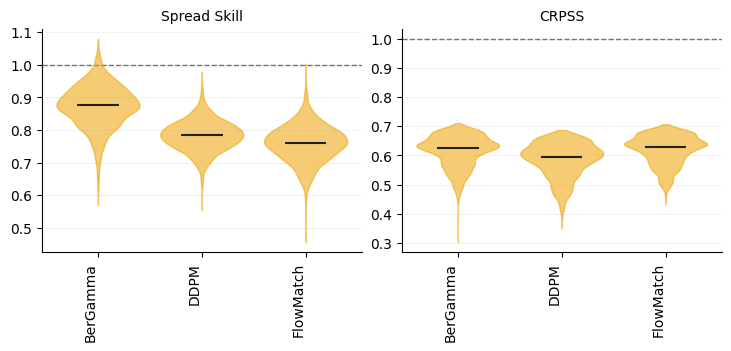

In [7]:
SERIES_COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100",
                 "#e87ba4", "#008300", "#6250d6", "#e34948"]


fig_violin, axes_violin = plot_metrics_violin(ds_metrics, ncols=2)
fig_violin.savefig(ROOT / "figures" / "prob_metrics_test_period_violin_plots.png", bbox_inches="tight", dpi=500)
